# Waze: User Churn Data (Machine Learning Stage)

Case study from the Google Advanced Data Analytics Professional Certificate (Course 5: The Nuts and Bolts of Machine Learning). Building and comparing random forest and XGBoost models to predict whether Waze users churn.

# **Predict user churn using machine learning**

## Plan

The model predicts whether a user will churn, to help Waze find what drives churn and improve retention. A false negative (a churner predicted to stay) means a missed chance to retain the user. A false positive (a retained user predicted to churn) costs little, since nobody is harmed by a wrong prediction. The benefits outweigh the risks, so proceed.

Features: usage, driving, and device data. Target: `label2` (1 = churned). Metric: recall, since missing a churner is the costlier error.

### Imports and data loading

In [1]:
# Import packages for data manipulation
import pandas as pd
import numpy as np

# Import packages for data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Show all columns
pd.set_option('display.max_columns', None)

# Import packages for data modeling
import sklearn.model_selection as ms
import sklearn.metrics as metrics
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier, plot_importance

In [2]:
# Load dataset into a dataframe
df0 = pd.read_csv('waze_dataset.csv')

## Analyze

### Data exploration

In [3]:
# Display first few rows
df0.head()

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
0,0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android
1,1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone
2,2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android
3,3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone
4,4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android


In [4]:
# Copy the dataframe
df = df0.copy()

In [5]:
# Get basic information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       14999 non-null  int64  
 1   label                    14299 non-null  object 
 2   sessions                 14999 non-null  int64  
 3   drives                   14999 non-null  int64  
 4   total_sessions           14999 non-null  float64
 5   n_days_after_onboarding  14999 non-null  int64  
 6   total_navigations_fav1   14999 non-null  int64  
 7   total_navigations_fav2   14999 non-null  int64  
 8   driven_km_drives         14999 non-null  float64
 9   duration_minutes_drives  14999 non-null  float64
 10  activity_days            14999 non-null  int64  
 11  driving_days             14999 non-null  int64  
 12  device                   14999 non-null  object 
dtypes: float64(3), int64(8), object(2)
memory usage: 1.5+ MB


## Construct

### Feature engineering

Creating features that describe how often and how far each user drives. Division by zero gives infinite values, which are converted to zero.

In [6]:
# Create km_per_driving_day column
df["km_per_driving_day"] = df["driven_km_drives"] / df["driving_days"]

# Get descriptive stats
df.describe()

,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,km_per_driving_day
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,1.499900e+04
mean,7499.000000,80.633776,67.281152,189.964447,1749.837789,121.605974,29.672512,4039.340921,1860.976012,15.537102,12.179879,inf
std,4329.982679,80.699065,65.913872,136.405128,1008.513876,148.121544,45.394651,2502.149334,1446.702288,9.004655,7.824036,NaN
min,0.000000,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000,3.022063e+00
25%,3749.500000,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000,1.672804e+02
50%,7499.000000,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000,3.231459e+02
75%,11248.500000,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000,7.579257e+02
max,14998.000000,743.000000,596.000000,1216.154633,3500.000000,1236.000000,415.000000,21183.401890,15851.727160,31.000000,30.000000,inf


In [7]:
# Convert infinite values to zero
df["km_per_driving_day"] = np.where(df["km_per_driving_day"] == np.inf, 0, df["km_per_driving_day"])

# Confirm that it worked
df.describe()

,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,km_per_driving_day
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,7499.000000,80.633776,67.281152,189.964447,1749.837789,121.605974,29.672512,4039.340921,1860.976012,15.537102,12.179879,578.963113
std,4329.982679,80.699065,65.913872,136.405128,1008.513876,148.121544,45.394651,2502.149334,1446.702288,9.004655,7.824036,1030.094384
min,0.000000,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000,0.000000
25%,3749.500000,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000,136.238895
50%,7499.000000,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000,272.889272
75%,11248.500000,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000,558.686918
max,14998.000000,743.000000,596.000000,1216.154633,3500.000000,1236.000000,415.000000,21183.401890,15851.727160,31.000000,30.000000,15420.234110


In [8]:
# Create percent_session_in_last_month column
df["percent_session_in_last_month"] = df["sessions"] / df["total_sessions"]

# Get descriptive stats
df.describe()

,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,km_per_driving_day,percent_session_in_last_month
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,7499.000000,80.633776,67.281152,189.964447,1749.837789,121.605974,29.672512,4039.340921,1860.976012,15.537102,12.179879,578.963113,0.449255
std,4329.982679,80.699065,65.913872,136.405128,1008.513876,148.121544,45.394651,2502.149334,1446.702288,9.004655,7.824036,1030.094384,0.286919
min,0.000000,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000,0.000000,0.000000
25%,3749.500000,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000,136.238895,0.196221
50%,7499.000000,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000,272.889272,0.423097
75%,11248.500000,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000,558.686918,0.687216
max,14998.000000,743.000000,596.000000,1216.154633,3500.000000,1236.000000,415.000000,21183.401890,15851.727160,31.000000,30.000000,15420.234110,1.530637


`professional_driver` is 1 for users with 60 or more drives and 15 or more driving days in the last month.

In [9]:
# Create professional_driver column
df["professional_driver"] = np.where((df["drives"] >= 60) & (df["driving_days"] >= 15), 1, 0)

In [11]:
# Create total_sessions_per_day column
df["total_sessions_per_day"] = df["total_sessions"] / df["n_days_after_onboarding"]

# Get descriptive stats
df["total_sessions_per_day"].describe()

count    14999.000000
mean         0.338698
std          1.314333
min          0.000298
25%          0.051037
50%          0.100775
75%          0.216269
max         39.763874
Name: total_sessions_per_day, dtype: float64

In [12]:
# Create km_per_hour column
df["km_per_hour"] = df["driven_km_drives"] / (df["duration_minutes_drives"] / 60)

In [13]:
# Create km_per_drive column
df["km_per_drive"] = df["driven_km_drives"] / df["drives"]

# Get descriptive stats
df["km_per_drive"].describe()

count    1.499900e+04
mean              inf
std               NaN
min      1.008775e+00
25%      3.323065e+01
50%      7.488006e+01
75%      1.854667e+02
max               inf
Name: km_per_drive, dtype: float64

In [14]:
# Convert infinite values to zero
df["km_per_drive"] = np.where(df["km_per_drive"] == np.inf, 0, df["km_per_drive"])

# Confirm that it worked
df["km_per_drive"].describe()

count    14999.000000
mean       232.817946
std        620.622351
min          0.000000
25%         32.424301
50%         72.854343
75%        179.347527
max      15777.426560
Name: km_per_drive, dtype: float64

In [15]:
# Create percent_of_sessions_to_favorite column
df["percent_of_sessions_to_favorite"] = (df["total_navigations_fav1"] + df["total_navigations_fav2"]) / df["total_sessions"]

# Get descriptive stats
df["percent_of_sessions_to_favorite"].describe()

count    14999.000000
mean         1.665439
std          8.865666
min          0.000000
25%          0.203471
50%          0.649818
75%          1.638526
max        777.563629
Name: percent_of_sessions_to_favorite, dtype: float64

### Missing values and outliers

Dropping the 700 rows with a missing `label` (under 5% of the data). Outliers are kept because tree-based models are resilient to them.

In [16]:
# Drop rows with missing values
df = df.dropna(subset="label")
df.isna().sum()

ID                                 0
label                              0
sessions                           0
drives                             0
total_sessions                     0
n_days_after_onboarding            0
total_navigations_fav1             0
total_navigations_fav2             0
driven_km_drives                   0
duration_minutes_drives            0
activity_days                      0
driving_days                       0
device                             0
km_per_driving_day                 0
percent_session_in_last_month      0
professional_driver                0
total_sessions_per_day             0
km_per_hour                        0
km_per_drive                       0
percent_of_sessions_to_favorite    0
dtype: int64

### Encoding

Convert `device` and the target to binary (iPhone and churned are 1).

In [18]:
# Create binary device2 column
df["device2"] = np.where(df["device"] == "iPhone", 1, 0)

# Create binary label2 column
df["label2"] = np.where(df["label"] == "churned", 1, 0)

### Feature selection

Dropping `ID`, which has no information about churn. `device` is left out of the features because `device2` replaces it.

In [19]:
# Drop ID column
df = df.drop("ID", axis=1)

### Evaluation metric

Checking class balance to choose an evaluation metric.

In [20]:
# Check class balance
df["label"].value_counts(normalize=True)

label
retained    0.822645
churned     0.177355
Name: proportion, dtype: float64

About 18% of users churned, so the data is imbalanced but can be modeled without rebalancing. A false positive costs almost nothing, so recall is the evaluation metric.

### Split the data

The data is split 60/20/20 into training, validation, and test sets, stratified on the target.

In [21]:
# Isolate features (device2 replaces device)
x = df.drop(["device", "label", "label2"], axis=1)

# Isolate target variable
y = df["label2"]

# Split into training and test sets
x_tr, x_test, y_tr, y_test = ms.train_test_split(x, y, test_size=0.2, stratify=y, random_state=7)

# Split into training and validation sets
x_train, x_val, y_train, y_val = ms.train_test_split(x_tr, y_tr, test_size=0.25, stratify=y_tr, random_state=7)

In [22]:
# Check the size of each set
for part in [x_train, x_val, x_test]:
    print(len(part))

8579
2860
2860


The sizes are as expected (8,579 / 2,860 / 2,860).

### Build models

#### **Build a random forest model**

Hyperparameters are tuned with cross-validation, and the model with the best recall is selected.

In [23]:
# Instantiate the random forest classifier
rf = RandomForestClassifier(random_state=7)

# Create a dictionary of hyperparameters to tune
cv_params = {
    "max_depth": [None],
    "max_features": [1.0],
    "max_samples": [1.0],
    "min_samples_leaf": [2],
    "min_samples_split": [2],
    "n_estimators": [300],
}

# Define a list of scoring metrics to capture
scoring = ["accuracy", "precision", "recall", "f1"]

# Instantiate the GridSearchCV object
rfgscv = ms.GridSearchCV(rf, cv_params, scoring=scoring, cv=4, refit="recall")

In [24]:
# Fit the model to the data
rfgscv.fit(x_train, y_train)

GridSearchCV(cv=4, estimator=RandomForestClassifier(random_state=7),
             param_grid={'max_depth': [None], 'max_features': [1.0],
                         'max_samples': [1.0], 'min_samples_leaf': [2],
                         'min_samples_split': [2], 'n_estimators': [300]},
             refit='recall', scoring=['accuracy', 'precision', 'recall', 'f1'])

In [25]:
# Examine best recall score
rfgscv.best_score_

0.13139936455311507

In [26]:
# Examine best parameters
rfgscv.best_params_

{'max_depth': None,
 'max_features': 1.0,
 'max_samples': 1.0,
 'min_samples_leaf': 2,
 'min_samples_split': 2,
 'n_estimators': 300}

Define a function that collects the cross-validation scores of the best model.

In [27]:
def make_results(model_name:str, model_object, metric:str):
    '''
    Arguments:
        model_name (string): what you want the model to be called in the output table
        model_object: a fit GridSearchCV object
        metric (string): precision, recall, f1, or accuracy

    Returns a pandas df with the F1, recall, precision, and accuracy scores
    for the model with the best mean 'metric' score across all validation folds.
    '''

    # Create dictionary that maps input metric to actual metric name in GridSearchCV
    metric_dict = {'precision': 'mean_test_precision',
                   'recall': 'mean_test_recall',
                   'f1': 'mean_test_f1',
                   'accuracy': 'mean_test_accuracy',
                   }

    # Get all the results from the CV and put them in a df
    cv_results = pd.DataFrame(model_object.cv_results_)

    # Isolate the row of the df with the max(metric) score
    best_estimator_results = cv_results.iloc[cv_results[metric_dict[metric]].idxmax(), :]

    # Extract accuracy, precision, recall, and f1 score from that row
    f1 = best_estimator_results.mean_test_f1
    recall = best_estimator_results.mean_test_recall
    precision = best_estimator_results.mean_test_precision
    accuracy = best_estimator_results.mean_test_accuracy

    # Create table of results
    table = pd.DataFrame({'model': [model_name],
                          'precision': [precision],
                          'recall': [recall],
                          'F1': [f1],
                          'accuracy': [accuracy],
                          },
                         )

    return table

In [28]:
# Get cross-validation scores
make_results("Random Forest", rfgscv, "recall")

,model,precision,recall,F1,accuracy
0,Random Forest,0.447304,0.131399,0.202613,0.816995


Recall is low (0.131), while accuracy is high (0.817).

#### **Build an XGBoost model**

In [29]:
# Instantiate the XGBoost classifier
xgb = XGBClassifier(objective="binary:logistic", random_state=7)

# Create a dictionary of hyperparameters to tune
cv_params = {
    "max_depth": [6, 12],
    "min_child_weight": [3, 5],
    "learning_rate": [0.01, 0.1],
    "n_estimators": [300],
}

# Define a list of scoring metrics to capture
scoring = ["accuracy", "precision", "recall", "f1"]

# Instantiate the GridSearchCV object
xgbcv = ms.GridSearchCV(xgb, cv_params, scoring=scoring, cv=4, refit="recall")

In [30]:
# Fit the model to the data
xgbcv.fit(x_train, y_train)

GridSearchCV(cv=4,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None,...
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=7, ...),
             param_grid={'learning_rate': [0.01, 0.1], 'max_depth': [6, 12],
                         'min_child_weight': [3, 5], 'n_estimators': [300]},
             refit='recall', scoring=['accuracy', 'precision', 'recall', 'f1'])

In [31]:
# Examine best recall score
xgbcv.best_score_

0.1688510153336096

In [32]:
# Examine best parameters
xgbcv.best_params_

{'learning_rate': 0.1,
 'max_depth': 12,
 'min_child_weight': 5,
 'n_estimators': 300}

In [33]:
# Get cross-validation scores
make_results("XGBoost", xgbcv, "recall")

,model,precision,recall,F1,accuracy
0,XGBoost,0.38821,0.168851,0.234863,0.805339


XGBoost has better recall than the random forest (0.169 vs. 0.131) with similar accuracy (0.805 vs. 0.817), though recall is still low.

## Execute

### Evaluate models

#### **Random forest**

In [34]:
# Use the best estimator to predict on the validation set
rf_pred = rfgscv.best_estimator_.predict(x_val)

In [35]:
def get_test_scores(model_name:str, preds, y_test_data):
    '''
    Generate a table of test scores.

    In:
        model_name (string): Your choice: how the model will be named in the output table
        preds: numpy array of test predictions
        y_test_data: numpy array of y_test data

    Out:
        table: a pandas df of precision, recall, f1, and accuracy scores for your model
    '''
    accuracy = metrics.accuracy_score(y_test_data, preds)
    precision = metrics.precision_score(y_test_data, preds)
    recall = metrics.recall_score(y_test_data, preds)
    f1 = metrics.f1_score(y_test_data, preds)

    table = pd.DataFrame({'model': [model_name],
                          'precision': [precision],
                          'recall': [recall],
                          'F1': [f1],
                          'accuracy': [accuracy]
                          })

    return table

In [36]:
# Get validation scores
rf_val_scores = get_test_scores("Random Forest Val", rf_pred, y_val)

# Combine with the cross-validation scores
rf_results = make_results("Random Forest", rfgscv, "recall")
xgb_results = make_results("XGBoost", xgbcv, "recall")
result_table = pd.concat([rf_results, xgb_results, rf_val_scores])
result_table

,model,precision,recall,F1,accuracy
0,Random Forest,0.447304,0.131399,0.202613,0.816995
0,XGBoost,0.388210,0.168851,0.234863,0.805339
0,Random Forest Val,0.474820,0.130178,0.204334,0.820280


Validation scores are close to the cross-validation scores (recall 0.130 vs. 0.131), and precision and accuracy are slightly higher, so the model isn't overfitting.

#### **XGBoost**

In [37]:
# Use the best estimator to predict on the validation set
xgb_pred = xgbcv.best_estimator_.predict(x_val)

# Get validation scores
xgb_val_scores = get_test_scores("XGB Val", xgb_pred, y_val)

# Append to the results table
result_table = pd.concat([result_table, xgb_val_scores])
result_table

,model,precision,recall,F1,accuracy
0,Random Forest,0.447304,0.131399,0.202613,0.816995
0,XGBoost,0.388210,0.168851,0.234863,0.805339
0,Random Forest Val,0.474820,0.130178,0.204334,0.820280
0,XGB Val,0.396040,0.157791,0.225670,0.808042


XGBoost's validation scores are also close to its cross-validation scores (recall 0.158 vs. 0.169, F1 0.226 vs. 0.235). It has the higher recall (0.158 vs. 0.130), so it's the champion model.

#### **Champion model on the test set**

In [39]:
# Use the champion model to predict on the test set
xgb_test_pred = xgbcv.best_estimator_.predict(x_test)

# Get test scores
xgb_test_scores = get_test_scores("XGB Champion", xgb_test_pred, y_test)

# Append to the results table
result_table = pd.concat([result_table, xgb_test_scores])
result_table

,model,precision,recall,F1,accuracy
0,Random Forest,0.447304,0.131399,0.202613,0.816995
0,XGBoost,0.388210,0.168851,0.234863,0.805339
0,Random Forest Val,0.474820,0.130178,0.204334,0.820280
0,XGB Val,0.396040,0.157791,0.225670,0.808042
0,XGB Champion,0.390000,0.153846,0.220651,0.807343


Test scores are close to the validation scores (recall 0.154 vs. 0.158, precision 0.390 vs. 0.396), so the champion model holds up on unseen data.

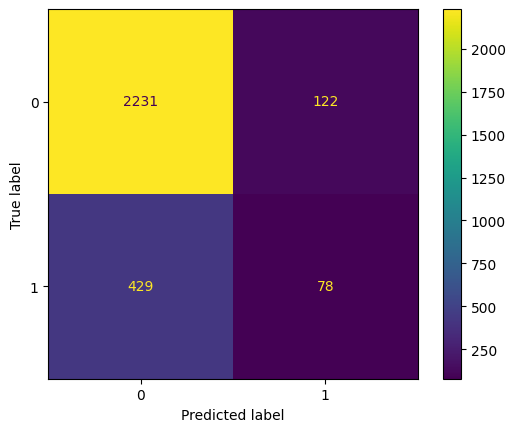

In [43]:
# Compute values for confusion matrix
cm = metrics.confusion_matrix(y_test, xgb_test_pred, labels=xgbcv.classes_)

# Create display of confusion matrix
disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=xgbcv.classes_)

# Plot confusion matrix
disp.plot()

The model makes about 3.5 times as many false negatives as false positives (429 vs. 122), and it finds only 15.4% of churners (78 of 507).

#### **Feature importances of champion model**

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

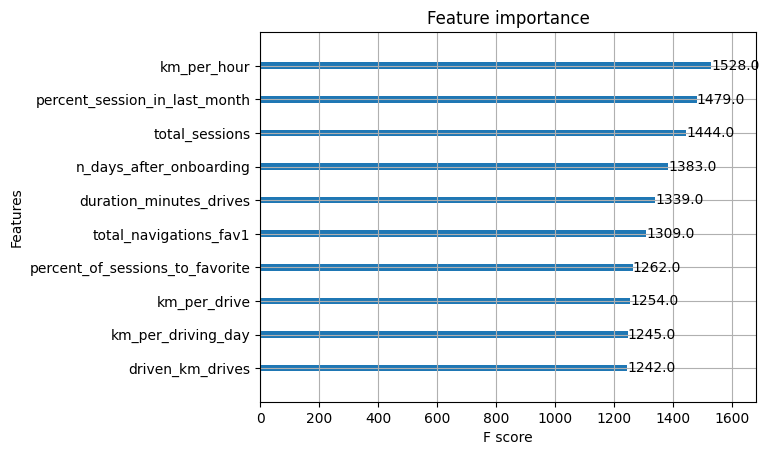

In [46]:
# Plot the 10 most important features
plot_importance(xgbcv.best_estimator_, max_num_features=10)

Importance is spread fairly evenly (F scores from 1,242 to 1,528), and no single feature dominates. Engineered features take five of the top 10 (`km_per_hour`, `percent_session_in_last_month`, `percent_of_sessions_to_favorite`, `km_per_drive`, `km_per_driving_day`), so feature engineering paid off.

### Conclusion

Recommend the model? Not yet. Recall is only about 0.15, so it finds roughly 1 in 7 churners, and its accuracy (0.807) is below the 0.823 you'd get by always predicting "retained". It's more useful for exploring what drives churn than for predicting it.

Validation set trade-off: The training set is smaller (60% instead of 80%), but model selection happens on the validation set, so the test set gives an honest final score.

Logistic regression vs. tree ensembles: Logistic regression is easier to interpret and needs less tuning. Tree ensembles capture non-linear patterns and feature interactions, and they handle outliers without extra work.

How to improve it: Tune a wider range of hyperparameters, address the class imbalance (class weights or resampling), and lower the decision threshold to trade precision for recall.

Helpful extra features: Month-by-month usage history, app version, region, crash or support records, and reasons for leaving.